In [75]:
import sys
import numpy as np
import pandas as pd
import sklearn

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)


Python: 3.12.2 (v3.12.2:6abddd9f6a, Feb  6 2024, 17:02:06) [Clang 13.0.0 (clang-1300.0.29.30)]
NumPy: 2.0.2
pandas: 2.3.3
scikit-learn: 1.6.1


# Step 2 — Load and Inspect

Student ID seed: 1399


In [76]:
raw = pd.read_csv("data/almaty_apartments_raw.csv")

ids = raw["listing_id"].drop_duplicates().sample(
    frac=0.9,
    random_state=1399
)

df = raw[raw["listing_id"].isin(ids)].reset_index(drop=True)

print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df.describe(include="all").T)

(1156, 11)
listing_id           object
listed_date          object
district             object
rooms                object
area_m2              object
floor                 int64
total_floors          int64
year_built          float64
building_type        object
ceiling_height_m    float64
price_kzt            object
dtype: object
listing_id            0
listed_date           0
district              0
rooms                 0
area_m2               0
floor                 0
total_floors          0
year_built           54
building_type         0
ceiling_height_m    133
price_kzt             0
dtype: int64
                   count unique         top freq         mean        std  min  \
listing_id          1156   1080   ALM-11147    3          NaN        NaN  NaN   
listed_date         1156    245  2026-04-21   11          NaN        NaN  NaN   
district            1156     48       Medeu  147          NaN        NaN  NaN   
rooms               1156      6           2  435          NaN     

In [77]:
print("listed_date:")
print(df["listed_date"].sample(10, random_state=1399).tolist())

print("\nrooms:")
print(df["rooms"].sample(10, random_state=1399).tolist())

print("\narea_m2:")
print(df["area_m2"].sample(10, random_state=1399).tolist())

print("\nprice_kzt:")
print(df["price_kzt"].sample(10, random_state=1399).tolist())


listed_date:
['2026-06-06', '2026-05-05', '2026-07-09', '2026-08-30', '2026-01-02', '2026-02-25', '2026-06-02', '2026-01-11', '2026-03-28', '2026-08-23']

rooms:
['2', 'studio', '2', '3', '2', '1', '1', '4', '2', '2']

area_m2:
['57.8', '29.9', '59.3', '78.1', '63.6', '34.3', '50.2', '106.5', '55.8', '51.1']

price_kzt:
['60870000', '16260000', '48780000', '84310000', '44300000', '17760000', '36930000', '88320000', '45840000', '49800000']


In [78]:
for col in ["rooms", "area_m2", "price_kzt"]:
    numeric = pd.to_numeric(df[col], errors="coerce")
    bad_values = df.loc[numeric.isna(), col].value_counts()

    print(f"\n--- {col}: non-numeric values ---")
    print(bad_values)
    


--- rooms: non-numeric values ---
rooms
studio    31
Name: count, dtype: int64

--- area_m2: non-numeric values ---
area_m2
46.8 m²     2
69,2        2
62,2        2
61.1 m²     2
35.4 m²     2
           ..
37,3        1
120,1       1
50.0 m²     1
66.3 m²     1
114.9 m²    1
Name: count, Length: 84, dtype: int64

--- price_kzt: non-numeric values ---
price_kzt
82 080 000 ₸    2
31,620,000      2
81 730 000 ₸    2
44 880 000 ₸    2
30,730,000      1
               ..
19,530,000      1
46 050 000 ₸    1
56 650 000 ₸    1
40 150 000 ₸    1
105,060,000     1
Name: count, Length: 88, dtype: int64


### Q1 — Wrong data types

 `listed_date` has type `object`, but it represents dates and should be converted to `datetime`.
 `rooms` has type `object` because it contains numeric values stored as text and the value `studio` (31 rows). It should be numeric after converting `studio` to 1.
 `area_m2` has type `object` because some values contain comma decimal separators and units such as `m²` (for example, `46,8 m²` and `61.1 m²`). It should be numeric.
 `price_kzt` has type `object` because some prices contain spaces, commas, and the `₸` symbol (for example, `82 080 000 ₸` and `31,620,000`). It should be numeric.

The other `object` columns such as `listing_id`, `district`, and `building_type` are categorical/text variables, so their current type is reasonable at this stage.

In [79]:
exact_duplicates = df.duplicated().sum()

repost_rows = df.duplicated(subset="listing_id", keep=False).sum()
repost_ids = df.loc[
    df.duplicated(subset="listing_id", keep=False),
    "listing_id"
].nunique()

print("Exact duplicate rows:", exact_duplicates)
print("Rows belonging to reposted listing IDs:", repost_rows)
print("Unique listing IDs with reposts:", repost_ids)

Exact duplicate rows: 33
Rows belonging to reposted listing IDs: 149
Unique listing IDs with reposts: 73


In [80]:
reposts = df[
    df.duplicated(subset="listing_id", keep=False)
].sort_values(["listing_id", "listed_date"])

reposts[
    ["listing_id", "listed_date", "district", "rooms", "area_m2", "price_kzt"]
].head(20)

,listing_id,listed_date,district,rooms,area_m2,price_kzt
967,ALM-10003,2026-05-04,Auezov,2,48.6,28320000
6,ALM-10003,2026-05-29,Auezov,2,48.6,26120000
816,ALM-10003,2026-05-29,Auezov,2,48.6,26120000
937,ALM-10009,2025-12-03,Medeuskiy,1,33.4,42700000
170,ALM-10009,2026-01-19,Medeuskiy,1,33.4,39400000
460,ALM-10016,2026-01-20,Auezov,1,39.7,35130000
438,ALM-10016,2026-01-29,Auezov,1,39.7,32100000
241,ALM-10021,2026-04-06,Alatau,3,71.3,32300000
596,ALM-10021,2026-05-09,Alatau,3,71.3,30090000
47,ALM-10056,2026-02-08,Bostandyk,4,107.2,101060000


### Q2 — Duplicates, reposts, and grain

I found **33 exact duplicate rows**.
 **149 rows** belong to listing IDs that appear more than once.
 There are **73 unique listing IDs with repeated records**.
 Exact duplicates and reposts are not the same problem. An exact duplicate has identical values in all columns, while a repost has the same `listing_id` but may have a different `listed_date`, price, or other values.
 These groups can overlap, so 33 and 149 should not simply be added together.

**Intended grain after cleaning:** one row represents one unique apartment listing (`listing_id`) after exact duplicates are removed and reposts are resolved.

In [81]:
print("floor:", df["floor"].min(), "to", df["floor"].max())
print("total_floors:", df["total_floors"].min(), "to", df["total_floors"].max())
print("year_built:", df["year_built"].min(), "to", df["year_built"].max())
print("ceiling_height_m:", df["ceiling_height_m"].min(), "to", df["ceiling_height_m"].max())

print("\nDistrict values:")
print(df["district"].value_counts())

print("\nBuilding types:")
print(df["building_type"].value_counts())
print("Rows where floor > total_floors:")
print((df["floor"] > df["total_floors"]).sum())

floor: -1 to 25
total_floors: 3 to 25
year_built: 0.0 to 2024.0
ceiling_height_m: 0.0 to 3.2

District values:
district
Medeu            147
Bostandyk        134
Turksib          129
Auezov           124
Zhetysu          122
Almaly           122
Alatau           103
Nauryzbay        102
Наурызбайский     10
medeu             10
turksib            9
AUEZOV             7
 Auezov            7
bostandyk          7
 Zhetysu           6
Nauryzbayskiy      6
auezov             6
Auezovskiy         6
TURKSIB            5
Bostandykskiy      5
nauryzbay          5
 Turksib           5
BOSTANDYK          5
Alatauskiy         5
Almalinskiy        4
ZHETYSU            4
 Alatau            4
ALMALY             4
Медеуский          4
 Bostandyk         4
almaly             4
MEDEU              4
 Medeu             4
Турксибский        3
Zhetysuskiy        3
 Almaly            3
Medeuskiy          3
Бостандыкский      3
NAURYZBAY          3
ALATAU             3
 Nauryzbay         2
zhetysu            

### Q3 — Validation Specification

| Column | Expected type | Validation rule |
|---|---|---|
| `listing_id` | string | Must be a valid listing identifier; one unique listing should remain after repost resolution |
| `listed_date` | datetime | Must be a valid date |
| `district` | category | Must map to one of the 8 canonical Almaty districts |
| `rooms` | numeric | Must be a positive integer; `studio` will be mapped to 1 |
| `area_m2` | numeric | Must be positive |
| `floor` | numeric | Must be positive and must not exceed `total_floors` |
| `total_floors` | numeric | Must be positive |
| `year_built` | numeric | Must represent a plausible construction year; sentinel values such as 0 are invalid |
| `building_type` | category | Must be a valid building type |
| `ceiling_height_m` | numeric | Must be positive; sentinel values such as 0 are invalid |
| `price_kzt` | numeric | Must be positive |

**Cross-field rule:** `floor <= total_floors`.

In [82]:
cleaning_log = []

before = len(df)

duplicate_count = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

after = len(df)

cleaning_log.append({
    "operation": "Remove exact duplicates",
    "rows_before": before,
    "rows_after": after,
    "cells_changed": 0
})

print("Exact duplicates removed:", duplicate_count)
print("Rows before:", before)
print("Rows after:", after)

Exact duplicates removed: 33
Rows before: 1156
Rows after: 1123


In [83]:
df["listed_date"] = pd.to_datetime(df["listed_date"], errors="coerce")

print("Invalid dates:", df["listed_date"].isna().sum())

Invalid dates: 0


In [84]:
before = len(df)

df = (
    df.sort_values("listed_date")
      .drop_duplicates(subset="listing_id", keep="last")
      .reset_index(drop=True)
)

after = len(df)

cleaning_log.append({
    "operation": "Resolve reposts — keep latest listed_date",
    "rows_before": before,
    "rows_after": after,
    "cells_changed": 0
})

print("Repost rows removed:", before - after)
print("Rows before:", before)
print("Rows after:", after)
print("Duplicate listing IDs remaining:", df["listing_id"].duplicated().sum())

Repost rows removed: 43
Rows before: 1123
Rows after: 1080
Duplicate listing IDs remaining: 0


### Repost strategy

The source file is shuffled, so row order cannot be used to decide which repost to keep. I converted `listed_date` to datetime, sorted the records by date, and kept the most recent record for each `listing_id`. This gives one row per unique listing and retains the latest available version of a reposted advertisement.

In [85]:
district_values = sorted(df["district"].dropna().unique())

print("Number of unique district values:", len(district_values))
print(district_values)

Number of unique district values: 48
[' Alatau ', ' Almaly ', ' Auezov ', ' Bostandyk ', ' Medeu ', ' Nauryzbay ', ' Turksib ', ' Zhetysu ', 'ALATAU', 'ALMALY', 'AUEZOV', 'Alatau', 'Alatauskiy', 'Almalinskiy', 'Almaly', 'Auezov', 'Auezovskiy', 'BOSTANDYK', 'Bostandyk', 'Bostandykskiy', 'MEDEU', 'Medeu', 'Medeuskiy', 'NAURYZBAY', 'Nauryzbay', 'Nauryzbayskiy', 'TURKSIB', 'Turksib', 'Turksibskiy', 'ZHETYSU', 'Zhetysu', 'Zhetysuskiy', 'alatau', 'almaly', 'auezov', 'bostandyk', 'medeu', 'nauryzbay', 'turksib', 'zhetysu', 'Алатауский', 'Алмалинский', 'Ауэзовский', 'Бостандыкский', 'Жетысуский', 'Медеуский', 'Наурызбайский', 'Турксибский']


In [86]:
before_district = df["district"].copy()

district_clean = df["district"].str.strip().str.lower()

district_mapping = {
   
    "alatau": "Alatau",
    "alatauskiy": "Alatau",
    "алатауский": "Alatau",

   
    "almaly": "Almaly",
    "almalinskiy": "Almaly",
    "алмалинский": "Almaly",

    
    "auezov": "Auezov",
    "auezovskiy": "Auezov",
    "ауэзовский": "Auezov",

 
    "bostandyk": "Bostandyk",
    "bostandykskiy": "Bostandyk",
    "бостандыкский": "Bostandyk",

   
    "medeu": "Medeu",
    "medeuskiy": "Medeu",
    "медеуский": "Medeu",

    
    "nauryzbay": "Nauryzbay",
    "nauryzbayskiy": "Nauryzbay",
    "наурызбайский": "Nauryzbay",

   
    "turksib": "Turksib",
    "turksibskiy": "Turksib",
    "турксибский": "Turksib",

    
    "zhetysu": "Zhetysu",
    "zhetysuskiy": "Zhetysu",
    "жетысуский": "Zhetysu"
}

df["district"] = district_clean.map(district_mapping)

cells_changed = (before_district != df["district"]).sum()

cleaning_log.append({
    "operation": "Standardize district names",
    "rows_before": len(df),
    "rows_after": len(df),
    "cells_changed": cells_changed
})

print("Cells changed:", cells_changed)
print("Unique districts:", df["district"].nunique())
print("Missing districts:", df["district"].isna().sum())
print(df["district"].value_counts())

Cells changed: 166
Unique districts: 8
Missing districts: 0
district
Medeu        161
Turksib      146
Bostandyk    145
Auezov       144
Almaly       127
Zhetysu      126
Nauryzbay    120
Alatau       111
Name: count, dtype: int64


In [87]:
before_rooms = df["rooms"].copy()
before_area = df["area_m2"].copy()
before_price = df["price_kzt"].copy()

df["rooms"] = (
    df["rooms"]
    .astype(str)
    .str.strip()
    .str.lower()
    .replace("studio", "1")
)

df["rooms"] = pd.to_numeric(df["rooms"], errors="coerce")

df["area_m2"] = (
    df["area_m2"]
    .astype(str)
    .str.replace("m²", "", regex=False)
    .str.strip()
    .str.replace(",", ".", regex=False)
)

df["area_m2"] = pd.to_numeric(df["area_m2"], errors="coerce")


df["price_kzt"] = (
    df["price_kzt"]
    .astype(str)
    .str.replace("₸", "", regex=False)
    .str.replace(" ", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["price_kzt"] = pd.to_numeric(df["price_kzt"], errors="coerce")


print("rooms dtype:", df["rooms"].dtype)
print("area_m2 dtype:", df["area_m2"].dtype)
print("price_kzt dtype:", df["price_kzt"].dtype)

print("\nMissing after conversion:")
print("rooms:", df["rooms"].isna().sum())
print("area_m2:", df["area_m2"].isna().sum())
print("price_kzt:", df["price_kzt"].isna().sum())

rooms dtype: int64
area_m2 dtype: float64
price_kzt dtype: int64

Missing after conversion:
rooms: 0
area_m2: 0
price_kzt: 0


In [88]:
rooms_changed = (before_rooms.astype(str) != df["rooms"].astype(str)).sum()
area_changed = (before_area.astype(str) != df["area_m2"].astype(str)).sum()
price_changed = (before_price.astype(str) != df["price_kzt"].astype(str)).sum()

cleaning_log.append({
    "operation": "Parse rooms to numeric",
    "rows_before": len(df),
    "rows_after": len(df),
    "cells_changed": rooms_changed
})

cleaning_log.append({
    "operation": "Parse area_m2 to numeric",
    "rows_before": len(df),
    "rows_after": len(df),
    "cells_changed": area_changed
})

cleaning_log.append({
    "operation": "Parse price_kzt to numeric",
    "rows_before": len(df),
    "rows_after": len(df),
    "cells_changed": price_changed
})

print("Rooms cells changed:", rooms_changed)
print("Area cells changed:", area_changed)
print("Price cells changed:", price_changed)

Rooms cells changed: 28
Area cells changed: 87
Price cells changed: 89


In [89]:
pd.DataFrame(cleaning_log)

,operation,rows_before,rows_after,cells_changed
0,Remove exact duplicates,1156,1123,0
1,Resolve reposts — keep latest listed_date,1123,1080,0
2,Standardize district names,1080,1080,166
3,Parse rooms to numeric,1080,1080,28
4,Parse area_m2 to numeric,1080,1080,87
5,Parse price_kzt to numeric,1080,1080,89


In [90]:
print(df.dtypes)
print("\nRows:", len(df))
print("Unique districts:", df["district"].nunique())
print("Missing districts:", df["district"].isna().sum())
print("Duplicate listing IDs:", df["listing_id"].duplicated().sum())

listing_id                  object
listed_date         datetime64[ns]
district                    object
rooms                        int64
area_m2                    float64
floor                        int64
total_floors                 int64
year_built                 float64
building_type               object
ceiling_height_m           float64
price_kzt                    int64
dtype: object

Rows: 1080
Unique districts: 8
Missing districts: 0
Duplicate listing IDs: 0


# Step 4 — Missing Values, Impossible Values & Outliers

## 4A — Sentinel Values

In [91]:
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    print(f"\n--- {col} ---")
    print("Min:", df[col].min())
    print("Max:", df[col].max())
    print("Missing:", df[col].isna().sum())


--- rooms ---
Min: 1
Max: 5
Missing: 0

--- area_m2 ---
Min: 25.3
Max: 879.0
Missing: 0

--- floor ---
Min: -1
Max: 25
Missing: 0

--- total_floors ---
Min: 3
Max: 25
Missing: 0

--- year_built ---
Min: 0.0
Max: 2024.0
Missing: 52

--- ceiling_height_m ---
Min: 0.0
Max: 3.2
Missing: 125

--- price_kzt ---
Min: 12210000
Max: 193000000
Missing: 0


In [92]:
print("floor = -1:", (df["floor"] == -1).sum())

print("year_built = 0:", (df["year_built"] == 0).sum())
print("year_built existing NaN:", df["year_built"].isna().sum())

print("ceiling_height_m min:", df["ceiling_height_m"].min())
print("ceiling_height_m = 0:", (df["ceiling_height_m"] == 0).sum())
print("ceiling_height_m existing NaN:", df["ceiling_height_m"].isna().sum())

floor = -1: 11
year_built = 0: 21
year_built existing NaN: 52
ceiling_height_m min: 0.0
ceiling_height_m = 0: 23
ceiling_height_m existing NaN: 125


In [93]:
sentinel_rules = {
    "floor": -1,
    "year_built": 0,
    "ceiling_height_m": 0
}

for col, sentinel in sentinel_rules.items():
    count = (df[col] == sentinel).sum()

    df.loc[df[col] == sentinel, col] = np.nan

    cleaning_log.append({
        "operation": f"Replace sentinel {sentinel} in {col} with NaN",
        "rows_before": len(df),
        "rows_after": len(df),
        "cells_changed": count
    })

    print(f"{col}: {count} sentinel values replaced")

floor: 11 sentinel values replaced
year_built: 21 sentinel values replaced
ceiling_height_m: 23 sentinel values replaced


In [94]:
print("floor missing:", df["floor"].isna().sum())
print("year_built missing:", df["year_built"].isna().sum())
print("ceiling_height_m missing:", df["ceiling_height_m"].isna().sum())

floor missing: 11
year_built missing: 73
ceiling_height_m missing: 148


## 4B — Impossible Values

I check cross-field consistency using the validation rules defined in Step 2.

In [95]:
impossible_floor = (
    df["floor"].notna() &
    (df["floor"] > df["total_floors"])
)

print("Rows where floor > total_floors:", impossible_floor.sum())

df.loc[
    impossible_floor,
    ["listing_id", "floor", "total_floors"]
]

Rows where floor > total_floors: 10


,listing_id,floor,total_floors
120,ALM-10851,13.0,12
147,ALM-10944,4.0,3
574,ALM-10420,11.0,9
616,ALM-10636,6.0,5
703,ALM-10628,6.0,5
756,ALM-10321,10.0,5
832,ALM-10266,13.0,12
885,ALM-10881,8.0,5
992,ALM-10074,11.0,9
1007,ALM-10695,14.0,12


In [96]:
count_impossible = impossible_floor.sum()

df.loc[impossible_floor, "floor"] = np.nan

cleaning_log.append({
    "operation": "Set impossible floor values to NaN",
    "rows_before": len(df),
    "rows_after": len(df),
    "cells_changed": count_impossible
})

print("Impossible floor values changed:", count_impossible)
print(
    "Remaining floor > total_floors:",
    (df["floor"] > df["total_floors"]).sum()
)

Impossible floor values changed: 10
Remaining floor > total_floors: 0


In [97]:
df["price_per_m2"] = df["price_kzt"] / df["area_m2"]
df["area_before_fix"] = df["area_m2"]

q1 = df["price_per_m2"].quantile(0.25)
q3 = df["price_per_m2"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

global_outliers = (
    (df["price_per_m2"] < lower) |
    (df["price_per_m2"] > upper)
)

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower fence:", lower)
print("Upper fence:", upper)
print("Global IQR outliers:", global_outliers.sum())

Q1: 520003.92705806345
Q3: 917958.3688159776
IQR: 397954.44175791414
Lower fence: -76927.73557880777
Upper fence: 1514890.0314528488
Global IQR outliers: 0


In [98]:
grouped = df["price_per_m2"].groupby(df["district"])

q1_group = grouped.transform(lambda x: x.quantile(0.25))
q3_group = grouped.transform(lambda x: x.quantile(0.75))

iqr_group = q3_group - q1_group

lower_group = q1_group - 1.5 * iqr_group
upper_group = q3_group + 1.5 * iqr_group

district_outliers = (
    (df["price_per_m2"] < lower_group) |
    (df["price_per_m2"] > upper_group)
)

print("Global IQR outliers:", global_outliers.sum())
print("District-grouped IQR outliers:", district_outliers.sum())

Global IQR outliers: 0
District-grouped IQR outliers: 12


In [99]:
flagged = df.loc[
    district_outliers,
    [
        "listing_id",
        "district",
        "rooms",
        "area_m2",
        "price_kzt",
        "price_per_m2"
    ]
].sort_values(["district", "price_per_m2"])

flagged

,listing_id,district,rooms,area_m2,price_kzt,price_per_m2
768,ALM-10909,Alatau,2,565.0,32610000,57716.814159
947,ALM-10440,Auezov,3,879.0,48370000,55028.441411
659,ALM-10264,Bostandyk,1,495.0,42680000,86222.222222
319,ALM-10058,Bostandyk,2,555.0,66270000,119405.405405
252,ALM-10072,Medeu,2,530.0,64270000,121264.150943
839,ALM-10605,Nauryzbay,2,54.3,36960000,680662.983425
1044,ALM-10659,Turksib,2,544.0,25030000,46011.029412
170,ALM-10405,Turksib,1,356.0,18830000,52893.258427
158,ALM-10276,Turksib,2,604.0,33630000,55678.807947
996,ALM-10069,Zhetysu,2,481.0,27710000,57609.147609


In [100]:
suspicious_area = district_outliers & (df["area_m2"] > 300)

check = df.loc[
    suspicious_area,
    ["listing_id", "district", "rooms", "area_m2", "price_kzt", "price_per_m2"]
].copy()

check["corrected_area"] = check["area_m2"] / 10
check["corrected_price_per_m2"] = (
    check["price_kzt"] / check["corrected_area"]
)

check

,listing_id,district,rooms,area_m2,price_kzt,price_per_m2,corrected_area,corrected_price_per_m2
2,ALM-10910,Zhetysu,3,736.0,54050000,73437.500000,73.6,7.343750e+05
158,ALM-10276,Turksib,2,604.0,33630000,55678.807947,60.4,5.567881e+05
170,ALM-10405,Turksib,1,356.0,18830000,52893.258427,35.6,5.289326e+05
252,ALM-10072,Medeu,2,530.0,64270000,121264.150943,53.0,1.212642e+06
319,ALM-10058,Bostandyk,2,555.0,66270000,119405.405405,55.5,1.194054e+06
502,ALM-10921,Zhetysu,3,668.0,38560000,57724.550898,66.8,5.772455e+05
659,ALM-10264,Bostandyk,1,495.0,42680000,86222.222222,49.5,8.622222e+05
768,ALM-10909,Alatau,2,565.0,32610000,57716.814159,56.5,5.771681e+05
947,ALM-10440,Auezov,3,879.0,48370000,55028.441411,87.9,5.502844e+05
996,ALM-10069,Zhetysu,2,481.0,27710000,57609.147609,48.1,5.760915e+05


In [101]:
bad_area_count = suspicious_area.sum()

df.loc[suspicious_area, "area_m2"] = (
    df.loc[suspicious_area, "area_m2"] / 10
)

df["price_per_m2"] = df["price_kzt"] / df["area_m2"]

cleaning_log.append({
    "operation": "Correct area values with misplaced decimal",
    "rows_before": len(df),
    "rows_after": len(df),
    "cells_changed": bad_area_count
})

print("Area values corrected:", bad_area_count)

Area values corrected: 11


In [102]:
grouped_after = df["price_per_m2"].groupby(df["district"])

q1_after = grouped_after.transform(lambda x: x.quantile(0.25))
q3_after = grouped_after.transform(lambda x: x.quantile(0.75))

iqr_after = q3_after - q1_after
lower_after = q1_after - 1.5 * iqr_after
upper_after = q3_after + 1.5 * iqr_after

outliers_after = (
    (df["price_per_m2"] < lower_after) |
    (df["price_per_m2"] > upper_after)
)

print("Outliers after area correction:", outliers_after.sum())

df.loc[
    outliers_after,
    [
        "listing_id",
        "district",
        "rooms",
        "area_m2",
        "price_kzt",
        "price_per_m2"
    ]
].sort_values(["district", "price_per_m2"])

Outliers after area correction: 1


,listing_id,district,rooms,area_m2,price_kzt,price_per_m2
839,ALM-10605,Nauryzbay,2,54.3,36960000,680662.983425


In [103]:
check_correction = df.loc[
    suspicious_area,
    [
        "listing_id",
        "district",
        "rooms",
        "area_before_fix",
        "area_m2",
        "price_kzt",
        "price_per_m2"
    ]
].copy()

district_median = df.groupby("district")["price_per_m2"].median()

check_correction["district_median_price_per_m2"] = (
    check_correction["district"].map(district_median)
)

check_correction

,listing_id,district,rooms,area_before_fix,area_m2,price_kzt,price_per_m2,district_median_price_per_m2
2,ALM-10910,Zhetysu,3,736.0,73.6,54050000,7.343750e+05,6.228148e+05
158,ALM-10276,Turksib,2,604.0,60.4,33630000,5.567881e+05,5.155426e+05
170,ALM-10405,Turksib,1,356.0,35.6,18830000,5.289326e+05,5.155426e+05
252,ALM-10072,Medeu,2,530.0,53.0,64270000,1.212642e+06,1.069185e+06
319,ALM-10058,Bostandyk,2,555.0,55.5,66270000,1.194054e+06,9.641956e+05
502,ALM-10921,Zhetysu,3,668.0,66.8,38560000,5.772455e+05,6.228148e+05
659,ALM-10264,Bostandyk,1,495.0,49.5,42680000,8.622222e+05,9.641956e+05
768,ALM-10909,Alatau,2,565.0,56.5,32610000,5.771681e+05,4.674419e+05
947,ALM-10440,Auezov,3,879.0,87.9,48370000,5.502844e+05,6.472077e+05
996,ALM-10069,Zhetysu,2,481.0,48.1,27710000,5.760915e+05,6.228148e+05


In [104]:
df.to_csv("data/almaty_apartments_clean.csv", index=False)

print("Saved: data/almaty_apartments_clean.csv")
print("Shape:", df.shape)

Saved: data/almaty_apartments_clean.csv
Shape: (1080, 13)


# Step 5 — Missing Data

## 5A — Train/Test Split

In [105]:
from sklearn.model_selection import train_test_split

NUMERIC = [
    "rooms",
    "area_m2",
    "floor",
    "total_floors",
    "year_built",
    "ceiling_height_m"
]

train, test = train_test_split(
    df,
    test_size=0.2,
    random_state=1399
)

train = train.copy()
test = test.copy()

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nMissing values in train:")
print(train[NUMERIC].isna().sum())

Train shape: (864, 13)
Test shape: (216, 13)

Missing values in train:
rooms                 0
area_m2               0
floor                16
total_floors          0
year_built           52
ceiling_height_m    115
dtype: int64


In [106]:
for col in ["ceiling_height_m", "year_built"]:
    print(f"\n--- {col} ---")

    rate = (
        train
        .assign(missing=train[col].isna())
        .groupby("building_type")["missing"]
        .mean()
    )

    print(rate)


--- ceiling_height_m ---
building_type
brick       0.140969
monolith    0.031359
panel       0.211429
Name: missing, dtype: float64

--- year_built ---
building_type
brick       0.079295
monolith    0.048780
panel       0.057143
Name: missing, dtype: float64


In [107]:
rows_removed_by_dropna = len(train) - len(train.dropna(subset=NUMERIC))

print(
    "Training rows that dropna() would remove:",
    rows_removed_by_dropna
)

Training rows that dropna() would remove: 172


In [108]:
from sklearn.metrics import mean_absolute_error

known = train[train["ceiling_height_m"].notna()]

hidden = known.sample(
    frac=0.15,
    random_state=1399
).index

rest = train.drop(index=hidden)

answers = train.loc[
    hidden,
    "ceiling_height_m"
]

print(len(hidden), "values hidden")

112 values hidden


In [109]:
global_median = rest["ceiling_height_m"].median()

pred_global = pd.Series(
    global_median,
    index=hidden
)

mae_global = mean_absolute_error(
    answers,
    pred_global
)

print("Global median:", global_median)
print("Global median MAE:", mae_global)

Global median: 2.77
Global median MAE: 0.14276785714285717


In [110]:
group_medians = (
    rest
    .groupby("building_type")["ceiling_height_m"]
    .median()
)

pred_group = train.loc[
    hidden,
    "building_type"
].map(group_medians)

mae_group = mean_absolute_error(
    answers,
    pred_group
)

print("Group medians:")
print(group_medians)

print("\nBuilding-type median MAE:", mae_group)

Group medians:
building_type
brick       2.93
monolith    2.86
panel       2.59
Name: ceiling_height_m, dtype: float64

Building-type median MAE: 0.07714285714285718


In [111]:

for col in ["ceiling_height_m", "year_built"]:
    print(f"\n--- Missing rate: {col} ---")

    rate = (
        train
        .assign(missing=train[col].isna())
        .groupby("building_type")["missing"]
        .mean()
    )

    print(rate)



global_median = rest["ceiling_height_m"].median()

pred_global = pd.Series(
    global_median,
    index=hidden
)

mae_global = mean_absolute_error(
    answers,
    pred_global
)



group_medians = (
    rest
    .groupby("building_type")["ceiling_height_m"]
    .median()
)

pred_group = train.loc[
    hidden,
    "building_type"
].map(group_medians)

mae_group = mean_absolute_error(
    answers,
    pred_group
)


print("\nGlobal median:", global_median)
print("Global median MAE:", mae_global)
print("Building-type median MAE:", mae_group)


--- Missing rate: ceiling_height_m ---
building_type
brick       0.140969
monolith    0.031359
panel       0.211429
Name: missing, dtype: float64

--- Missing rate: year_built ---
building_type
brick       0.079295
monolith    0.048780
panel       0.057143
Name: missing, dtype: float64

Global median: 2.77
Global median MAE: 0.14276785714285717
Building-type median MAE: 0.07714285714285718


In [112]:

ceiling_medians = (
    train
    .groupby("building_type")["ceiling_height_m"]
    .median()
)

train["ceiling_height_m"] = train["ceiling_height_m"].fillna(
    train["building_type"].map(ceiling_medians)
)

test["ceiling_height_m"] = test["ceiling_height_m"].fillna(
    test["building_type"].map(ceiling_medians)
)



year_median = train["year_built"].median()

train["year_built"] = train["year_built"].fillna(year_median)
test["year_built"] = test["year_built"].fillna(year_median)



floor_medians = (
    train
    .groupby("total_floors")["floor"]
    .median()
)

train["floor"] = train["floor"].fillna(
    train["total_floors"].map(floor_medians)
)

test["floor"] = test["floor"].fillna(
    test["total_floors"].map(floor_medians)
)


floor_global_median = train["floor"].median()

train["floor"] = train["floor"].fillna(floor_global_median)
test["floor"] = test["floor"].fillna(floor_global_median)


print("NaN left in TRAIN:")
print(train[NUMERIC].isna().sum())

print("\nNaN left in TEST:")
print(test[NUMERIC].isna().sum())

NaN left in TRAIN:
rooms               0
area_m2             0
floor               0
total_floors        0
year_built          0
ceiling_height_m    0
dtype: int64

NaN left in TEST:
rooms               0
area_m2             0
floor               0
total_floors        0
year_built          0
ceiling_height_m    0
dtype: int64


### Missing-data decisions

 `ceiling_height_m` appears MAR because the missing rate varies substantially by `building_type` (about 3.1% to 21.1%). The building-type median also performed better in the masking experiment: MAE = 0.0771 versus 0.1428 for the global median. Therefore, I used the median within each `building_type`.

 `year_built` has more similar missing rates across building types (about 4.9% to 7.9%), so the pattern looks closer to MCAR. I filled missing values with the global median calculated from the training set only.

 `floor` was filled using the median floor within each `total_floors` group, calculated from the training set only. This keeps the imputed floor consistent with the size of the building.

All fill values were learned from the training set only and then applied to both the training and test sets to avoid data leakage.

# Step 6 — Scaling and Encoding

## 6A — Effect of Outliers on Scaling

In [113]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

for scaler in (StandardScaler(), MinMaxScaler(), RobustScaler()):
    scaled = scaler.fit_transform(
        train[["area_before_fix"]]
    ).ravel()

    q1, q3 = np.percentile(scaled, [25, 75])

    print(
        f"{type(scaler).__name__:15s} "
        f"IQR={q3 - q1:.3f}  "
        f"min={scaled.min():.2f}  "
        f"max={scaled.max():.2f}"
    )

StandardScaler  IQR=0.602  min=-0.78  max=14.64
MinMaxScaler    IQR=0.039  min=0.00  max=1.00
RobustScaler    IQR=1.000  min=-1.00  max=24.62


In [114]:

scaler_train = StandardScaler()

train_area_scaled = scaler_train.fit_transform(
    train[["area_m2"]]
)

test_area_scaled_correct = scaler_train.transform(
    test[["area_m2"]]
)

combined_area = pd.concat([
    train[["area_m2"]],
    test[["area_m2"]]
])

scaler_all = StandardScaler()
scaler_all.fit(combined_area)

test_area_scaled_leakage = scaler_all.transform(
    test[["area_m2"]]
)


print(
    "Test mean — scaler fitted on TRAIN only:",
    test_area_scaled_correct.mean()
)

print(
    "Test mean — scaler fitted on TRAIN + TEST:",
    test_area_scaled_leakage.mean()
)

Test mean — scaler fitted on TRAIN only: -0.08819000298471308
Test mean — scaler fitted on TRAIN + TEST: -0.07080707387908666


The second approach is incorrect because the scaler learns information from the test set. This causes data leakage, even if the numerical difference between the two test means is small.

In [115]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CATEGORICAL = [
    "district",
    "building_type"
]

pre = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    (
        "cat",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ),
        CATEGORICAL
    ),
])

X_train = pre.fit_transform(
    train[NUMERIC + CATEGORICAL]
)

X_test = pre.transform(
    test[NUMERIC + CATEGORICAL]
)

model = LinearRegression().fit(
    X_train,
    train["price_kzt"]
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print(
    "NaN:",
    np.isnan(X_train).sum(),
    np.isnan(X_test).sum()
)

print(
    "Test R2:",
    model.score(
        X_test,
        test["price_kzt"]
    )
)

X_train shape: (864, 17)
X_test shape: (216, 17)
NaN: 0 0
Test R2: 0.9165385853418045


### Step 6 Summary

`MinMaxScaler` compressed most values into a relatively small part of the [0, 1] range because it depends on the minimum and maximum values. `StandardScaler` was also affected by the extreme values because it uses the mean and standard deviation. `RobustScaler` was the most resistant to outliers because it uses the median and IQR, so I would prefer it if the outliers had not been cleaned.

When `StandardScaler` was fitted only on the training set, the mean of the scaled test data was -0.0882. When it was fitted using both train and test data, the mean became -0.0708. The second approach is incorrect because information from the test set leaks into preprocessing.

The final matrices had shapes (864, 17) and (216, 17), with 0 NaN values in both. The test R² was 0.9165.

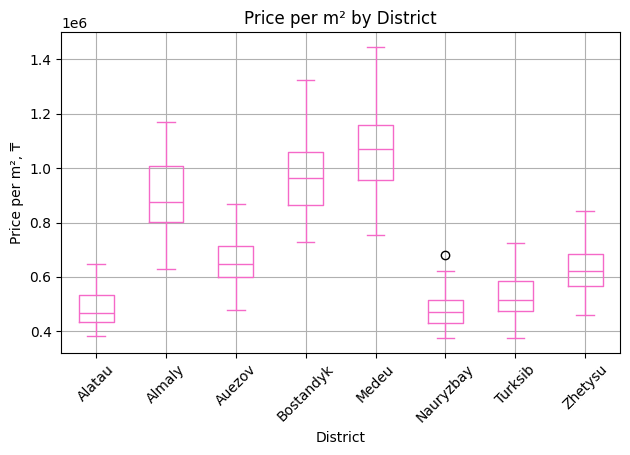

district
Medeu        1.069185e+06
Bostandyk    9.641956e+05
Almaly       8.763006e+05
Auezov       6.472077e+05
Zhetysu      6.228148e+05
Turksib      5.155426e+05
Nauryzbay    4.696046e+05
Alatau       4.674419e+05
Name: price_per_m2, dtype: float64


In [116]:
import matplotlib.pyplot as plt

df.boxplot(column="price_per_m2", by="district", rot=45,color="#F569C8")

plt.ylabel("Price per m², ₸")
plt.xlabel("District")
plt.title("Price per m² by District")
plt.suptitle("")
plt.tight_layout()
plt.show()

district_medians = (
    df.groupby("district")["price_per_m2"]
    .median()
    .sort_values(ascending=False)
)

print(district_medians)

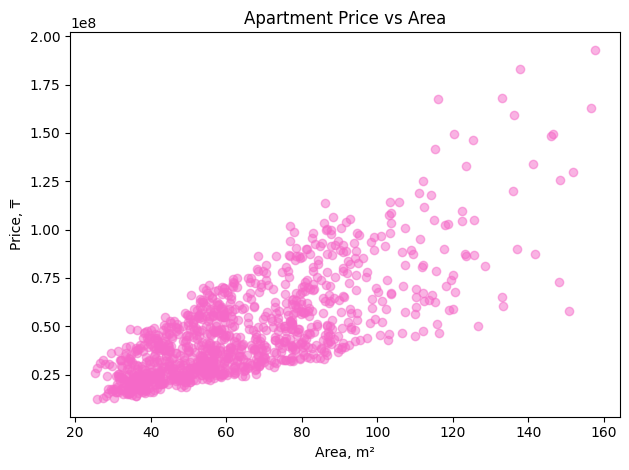

Correlation between area and price: 0.748751214174815


In [117]:
plt.scatter(df["area_m2"], df["price_kzt"], alpha=0.5,color="#F569C8")

plt.xlabel("Area, m²")
plt.ylabel("Price, ₸")
plt.title("Apartment Price vs Area")
plt.tight_layout()
plt.show()

correlation = df["area_m2"].corr(df["price_kzt"])

print("Correlation between area and price:", correlation)

The correlation between apartment area and price is 0.749, which indicates a fairly strong positive relationship: larger apartments tend to have higher prices.

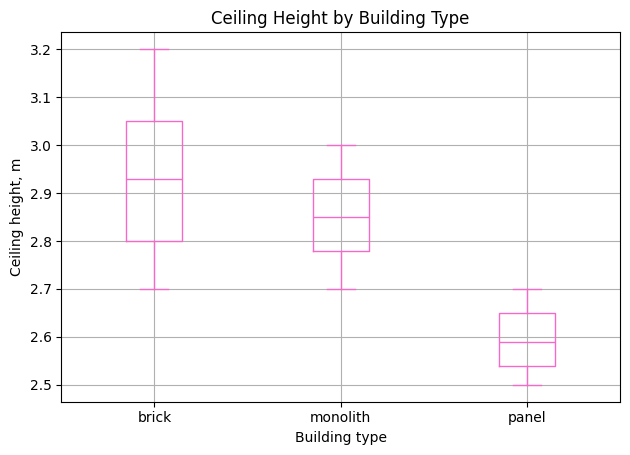

building_type
brick       2.93
monolith    2.85
panel       2.59
Name: ceiling_height_m, dtype: float64


In [118]:
df.boxplot(
    column="ceiling_height_m",
    by="building_type",
    color="#F569C8"
)

plt.ylabel("Ceiling height, m")
plt.xlabel("Building type")
plt.title("Ceiling Height by Building Type")
plt.suptitle("")
plt.tight_layout()
plt.show()

ceiling_medians = (
    df.groupby("building_type")["ceiling_height_m"]
    .median()
)

print(ceiling_medians)

The median ceiling height is highest in brick buildings at 2.93 m, followed by monolith buildings at 2.85 m, while panel buildings have the lowest median ceiling height at 2.59 m.

In [119]:
cleaning_log_df = pd.DataFrame(cleaning_log)

cleaning_log_df

,operation,rows_before,rows_after,cells_changed
0,Remove exact duplicates,1156,1123,0
1,Resolve reposts — keep latest listed_date,1123,1080,0
2,Standardize district names,1080,1080,166
3,Parse rooms to numeric,1080,1080,28
4,Parse area_m2 to numeric,1080,1080,87
5,Parse price_kzt to numeric,1080,1080,89
6,Replace sentinel -1 in floor with NaN,1080,1080,11
7,Replace sentinel 0 in year_built with NaN,1080,1080,21
8,Replace sentinel 0 in ceiling_height_m with NaN,1080,1080,23
9,Set impossible floor values to NaN,1080,1080,10


In [120]:
import os

print(
    "Clean CSV exists:",
    os.path.exists("data/almaty_apartments_clean.csv")
)

Clean CSV exists: True


In [121]:
!git log --oneline

ab5212d (HEAD -> main) Complete EDA and final preprocessing
ae40f8c Complete missing data handling
de9a35c Complete data cleaning
1ad7b0d Initial commit
